<div style="background:#152238;color:white;border-radius:14px;padding:28px 32px;">
 <div style="color:#9de2dc;letter-spacing:2px;font-size:12px;font-weight:bold;">AI ALGORITHMS · MDP AND RL LAB</div>
 <h1 style="text-align:center;color:white;margin:18px 0 12px;">Lab 5 — Markov Decision Processes and Reinforcement Learning</h1>
 <div style="text-align:center;color:#eebe5c;letter-spacing:2px;font-size:14px;font-weight:bold;">Frozen Lake</div>
</div>

## Learning objectives

- Describe Frozen Lake as a Markov decision process (MDP), using the Gymnasium API.
- Compute an optimal policy from a known model, with value iteration and policy iteration.
- Learn a policy from interaction with Q-learning, without reading the model.
- Compare the three methods with indicators that you choose, and discuss the effect of a larger grid.

## Contents

1. [Part I — Frozen Lake as a Markov decision process](#part-i)
   - I.1 — Discover the Gymnasium API
   - I.2 — The Frozen Lake environment
   - I.3 — Explore the environment
2. [Part II — Plan with a known model](#part-ii)
   - II.1 — Value iteration
   - II.2 — Policy iteration
3. [Part III — Learn from interaction: Q-learning](#part-iii)
4. [Part IV — Compare the methods and change the scale](#part-iv)
   - IV.1 — Compare the three methods
   - IV.2 — A larger lake
5. [Notebook submission](#submission)

Write your own implementations and explanations. The provided cells show how to use Gymnasium and how to display an episode; the algorithms are your work.

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:16px 0;">
<strong style="color:#7051a4;">Notebook submission</strong>
<p>Submit your completed notebook on <strong>DLV by 20 December 2026</strong>. Your grade is based entirely on the work you submit for Parts I–IV. You may include supporting files with the notebook.</p>
</div>

## Reading the task labels

<span style="color:#a85315;font-weight:bold;">IMPLEMENT · I</span> — write or adapt code.

<span style="color:#7051a4;font-weight:bold;">EXPLAIN · Q</span> — justify choices, interpret results and answer in writing.

<span style="color:#087f8c;font-weight:bold;">OBSERVE · O</span> — read, run and understand a provided example.

The words and labels identify the type of work as well as the colors.

## Working environment

Use Python in Jupyter or Google Colab. This lab uses `gymnasium`, `numpy` and `matplotlib`.
Displaying the lake as an image also needs `pygame`, which is installed with `gymnasium[toy-text]`.
If a package is missing, use the commented installation line in the first code cell.

In [1]:
# If a package is missing in this notebook environment:
# %pip install "gymnasium[toy-text]" matplotlib

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

print("Gymnasium version:", gym.__version__)

Gymnasium version: 1.4.0


<a id="part-i"></a>
# Part I — Frozen Lake as a Markov decision process

An agent must cross a frozen lake, from a start cell to a goal cell, without falling into a hole.
The ice is slippery: the agent does not always move in the direction it chooses.

This problem is a Markov decision process (MDP). In this part, you discover the library that provides
the lake, then you identify the elements of the MDP: states, actions, transition probabilities and rewards.

## I.1 — Discover the Gymnasium API

<div class="csp-task-panel" data-task-kind="OBSERVE" style="border-left:5px solid #087f8c;background:#eef9f8;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#087f8c;">OBSERVE · O1 · Read and run the Gymnasium examples</strong>
<p><a href="https://gymnasium.farama.org">Gymnasium</a> is a Python library of environments for reinforcement learning. It is a maintained fork of OpenAI Gym. All its environments are used through the same interface:</p>
<ul>
<li><code>gym.make(name)</code> creates an environment. The name ends with a version number, as in <code>FrozenLake-v1</code>.</li>
<li>The <strong>observation space</strong> describes what the agent observes. In Frozen Lake, it is the state.</li>
<li>The <strong>action space</strong> describes the actions that the agent can choose.</li>
<li><code>reset()</code> starts a new episode. It returns the first observation and an <code>info</code> dictionary.</li>
<li><code>step(action)</code> plays one action. It returns the five values below.</li>
</ul>
<table style="border-collapse:collapse;width:100%;color:#182b45;">
<thead>
<tr>
<th style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Value returned by <code>step</code></th>
<th style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Meaning</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>observation</code></td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">The new state.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>reward</code></td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">The reward received for this step.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>terminated</code></td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>True</code> when the episode ends in a terminal state. In Frozen Lake: a hole or the goal.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>truncated</code></td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>True</code> when the episode is stopped by a time limit. In Frozen Lake: after 100 steps, or 200 steps on the 8 × 8 lake.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;"><code>info</code></td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Additional information. In Frozen Lake: the probability of the transition that occurred.</td>
</tr>
</tbody>
</table>
<p>Read the three cells below, run them, and make sure that you can explain each value they display. More details are in the <a href="https://gymnasium.farama.org">Gymnasium documentation</a>.</p>

</div>

First observation: 0
Info: {'prob': 1}


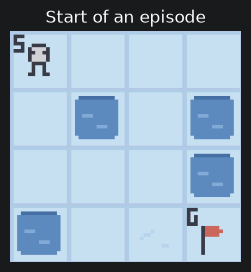

In [2]:
# Create the 4 x 4 Frozen Lake. render_mode="rgb_array" lets us display the lake as an image.
env = gym.make("FrozenLake-v1", render_mode="rgb_array")

# reset() starts a new episode. It returns the first observation and an info dictionary.
observation, info = env.reset(seed=0)
print("First observation:", observation)
print("Info:", info)


def show_frame(env, title=None):
    """Display the current image of the lake."""
    plt.figure(figsize=(3, 3))
    plt.imshow(env.render())
    plt.axis("off")
    if title is not None:
        plt.title(title)
    plt.show()


show_frame(env, "Start of an episode")

Observation space: Discrete(16)
Action space: Discrete(4)
observation: 4
reward: 0
terminated: False
truncated: False
info: {'prob': 0.33333333333333337}


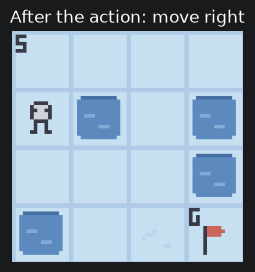

In [3]:
# The two spaces describe what the agent can observe and what it can do.
print("Observation space:", env.observation_space)   # 16 states, numbered from 0 to 15
print("Action space:", env.action_space)             # 4 actions, numbered from 0 to 3

# step(action) plays one action and returns five values.
observation, reward, terminated, truncated, info = env.step(2)   # 2 = move right
print("observation:", observation)
print("reward:", reward)
print("terminated:", terminated)
print("truncated:", truncated)
print("info:", info)

# The ice is slippery: the agent does not always arrive where it aimed.
show_frame(env, "After the action: move right")

In [4]:
# Gymnasium contains many other environments. Their names are stored in a registry.
names = list(gym.envs.registry.keys())
print("Number of registered environments:", len(names))
print("Frozen Lake environments:", [name for name in names if "FrozenLake" in name])

Number of registered environments: 63
Frozen Lake environments: ['FrozenLake-v1', 'FrozenLake8x8-v1']


## I.2 — The Frozen Lake environment

<div class="csp-task-panel" data-task-kind="OBSERVE" style="border-left:5px solid #087f8c;background:#eef9f8;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#087f8c;">OBSERVE · O2 · Read the description and run the Frozen Lake examples</strong>
<p>The cells below describe the lake as an MDP: the grid and its states, the four actions, the slippery ice and the rewards. Read each description, run the code cell that follows it, and compare what it displays with the text.</p>

</div>

**The grid and the states.** The lake is a 4 × 4 grid. Each cell is a state. The states are numbered from 0 to 15, row by row: the state of a cell is 4 × row + column.

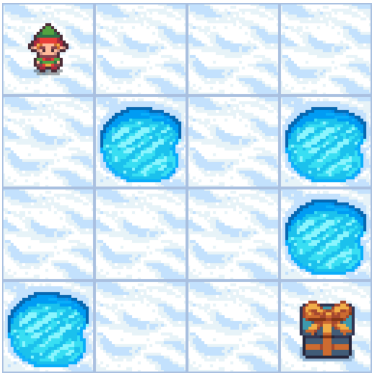

| Letter | Cell | Effect |
|:--|:--|:--|
| S | Start | The agent starts every episode here, in state 0. |
| F | Frozen | A safe cell. |
| H | Hole | The episode ends, without reward. |
| G | Goal | The episode ends, with a reward of 1. |

In [5]:
# The map of the lake. Each cell shows its letter and the number of its state.
layout = env.unwrapped.desc
n_rows, n_columns = layout.shape
for row in range(n_rows):
    cells = []
    for column in range(n_columns):
        state = row * n_columns + column
        cells.append(f"{layout[row, column].decode()}({state:2d})")
    print("   ".join(cells))

S( 0)   F( 1)   F( 2)   F( 3)
F( 4)   H( 5)   F( 6)   H( 7)
F( 8)   F( 9)   F(10)   H(11)
H(12)   F(13)   F(14)   G(15)


**The actions.** The agent has four actions: 0 = left, 1 = down, 2 = right and 3 = up.
At the edge of the grid, a move towards the outside leaves the agent in the same cell.

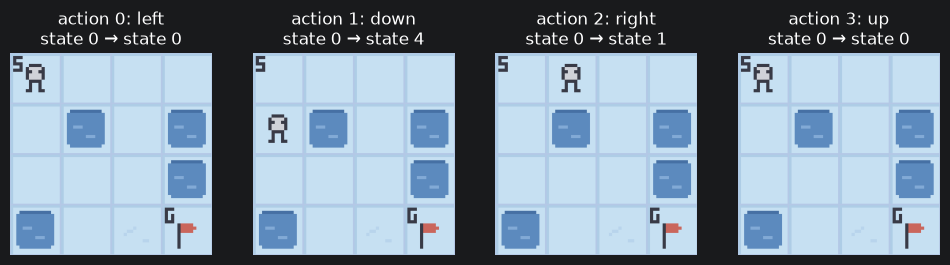

In [6]:
ACTION_NAMES = {0: "left", 1: "down", 2: "right", 3: "up"}
ACTION_ARROWS = {0: "←", 1: "↓", 2: "→", 3: "↑"}

# On the deterministic lake (is_slippery=False), an action has only one outcome.
# Play each of the four actions from the start state.
deterministic_env = gym.make("FrozenLake-v1", render_mode="rgb_array", is_slippery=False)
figure, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for action in range(4):
    deterministic_env.reset()
    observation, reward, terminated, truncated, info = deterministic_env.step(action)
    axes[action].imshow(deterministic_env.render())
    axes[action].set_title(f"action {action}: {ACTION_NAMES[action]}\nstate 0 → state {observation}")
    axes[action].axis("off")
plt.show()

**The slippery ice.** By default (`is_slippery=True`), an action has three possible outcomes, each with probability 1/3:

- the agent moves in the chosen direction;
- the agent slips to one side, at 90° from the chosen direction;
- the agent slips to the other side, also at 90° from the chosen direction.

The agent never moves in the direction opposite to its choice. With `is_slippery=False`, the lake is deterministic: the agent always moves in the chosen direction.

Example: in state 6, the agent chooses action 0 (left). It moves left to state 5, which is a hole, with probability 1/3. It slips up to state 2 with probability 1/3, and down to state 10 with probability 1/3.

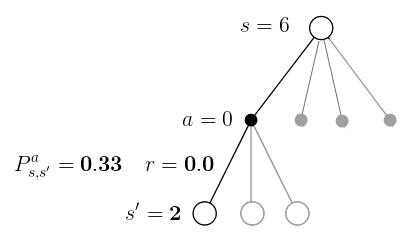

**The rewards.** The agent receives a reward of 1 for the step that reaches the goal. Every other step gives 0: there is no penalty for a move or for a hole. Such a reward is called sparse.

Gymnasium stores these probabilities and rewards in a model: `P[state][action]` is the list of the possible outcomes.

In [7]:
# The model of the environment. P[state][action] is the list of the possible outcomes.
# Each outcome is (probability, next state, reward, terminated).
P = env.unwrapped.P

print("State 6, action 0 (left), on the slippery lake:")
for probability, next_state, reward, terminated in P[6][0]:
    print(f"   probability {probability:.2f} -> next state {next_state:2d} | "
          f"reward {reward} | terminated {terminated}")

print("State 14, action 2 (right), on the slippery lake:")
for probability, next_state, reward, terminated in P[14][2]:
    print(f"   probability {probability:.2f} -> next state {next_state:2d} | "
          f"reward {reward} | terminated {terminated}")

print("State 6, action 0 (left), on the deterministic lake:")
print("  ", deterministic_env.unwrapped.P[6][0])

State 6, action 0 (left), on the slippery lake:
   probability 0.33 -> next state  2 | reward 0 | terminated False
   probability 0.33 -> next state  5 | reward 0 | terminated True
   probability 0.33 -> next state 10 | reward 0 | terminated False
State 14, action 2 (right), on the slippery lake:
   probability 0.33 -> next state 14 | reward 0 | terminated False
   probability 0.33 -> next state 15 | reward 1 | terminated True
   probability 0.33 -> next state 10 | reward 0 | terminated False
State 6, action 0 (left), on the deterministic lake:
   [(1.0, 5, 0, True)]


**Where to find the information**

| Information | How to get it |
|:--|:--|
| States | `env.observation_space` |
| Actions | `env.action_space` |
| Map of the lake | `env.unwrapped.desc` |
| Transition probabilities, rewards and terminal outcomes | `env.unwrapped.P` |
| First state of an episode | `env.reset()` |
| Result of an action | `env.step(action)` |
| A random action | `env.action_space.sample()` |
| Image of the lake | `env.render()` |
| Release of the environment | `env.close()` |

## I.3 — Explore the environment

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I1 · Explore Frozen Lake with your own code</strong>
<p>Work on the slippery lake. Write a short piece of code for each step.</p>
<p><strong>1. Read the model.</strong> For a state and an action of your choice, display every possible outcome. Then use the model to list the terminal states.</p>
<p><strong>2. Play one episode with random actions.</strong> Display each step: state, action, next state, reward, <code>terminated</code> and <code>truncated</code>. At the end, display the total reward, the number of steps and whether the agent reached the goal.</p>
<p><strong>3. Write a function <code>evaluate_policy</code>.</strong> It plays many episodes with a policy and returns its success rate: the fraction of episodes that reach the goal. You will reuse it in Parts II, III and IV.</p>
<p><strong>4. Evaluate simple policies.</strong> Measure the success rate of random actions, and of one fixed policy of your choice, for example always moving right.</p>
<p>In this lab, a policy can be stored as an array that gives one action for each state. The parameters of your function are your choice.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q1 · Describe the MDP and interpret your first results</strong>
<ol>
<li>Describe Frozen Lake as an MDP: its states, actions, transition model, rewards and terminal states.</li>
<li>Explain the difference between <code>terminated</code> and <code>truncated</code>. Which one did you observe in your episode?</li>
<li>Present the success rates of your simple policies. Explain why they are low, and why one episode is not enough to judge a policy.</li>
</ol>

</div>

In [8]:
P = env.unwrapped.P
n_states = env.observation_space.n
n_actions = env.action_space.n

state_choice = 6
action_choice = 0
print(f"State {state_choice}, action {action_choice} ({ACTION_NAMES[action_choice]}):")
for prob, next_s, reward, done in P[state_choice][action_choice]:
    print(f"  p={prob:.4f} -> next_state={next_s}, reward={reward}, terminated={done}")

terminal_states = []
for s in range(n_states):
    for a in range(n_actions):
        for prob, next_s, reward, done in P[s][a]:
            if next_s == s and done:
                if s not in terminal_states:
                    terminal_states.append(s)
print("Terminal states:", sorted(terminal_states))


State 6, action 0 (left):
  p=0.3333 -> next_state=2, reward=0, terminated=False
  p=0.3333 -> next_state=5, reward=0, terminated=True
  p=0.3333 -> next_state=10, reward=0, terminated=False
Terminal states: [5, 7, 11, 12, 15]


In [9]:
env_explore = gym.make("FrozenLake-v1", render_mode="rgb_array")
state, info = env_explore.reset(seed=42)
total_reward = 0
steps = 0
done = False
while not done:
    action = env_explore.action_space.sample()
    next_state, reward, terminated, truncated, info = env_explore.step(action)
    print(f"Step {steps+1:2d}: state {state:2d} -> action {ACTION_NAMES[action]:<5} -> next state {next_state:2d} | reward {reward} | terminated {terminated} | truncated {truncated}")
    total_reward += reward
    state = next_state
    steps += 1
    done = terminated or truncated
print(f"\nEpisode ended after {steps} steps. Total reward: {total_reward}. Goal reached: {reward == 1.0}.")


Step  1: state  0 -> action right -> next state  1 | reward 0 | terminated False | truncated False
Step  2: state  1 -> action left  -> next state  5 | reward 0 | terminated True | truncated False

Episode ended after 2 steps. Total reward: 0. Goal reached: False.


In [10]:
def evaluate_policy(env, policy, n_episodes=1000, seed=0):
    successes = 0
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done = False
        while not done:
            action = int(policy[state])
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
        if reward == 1.0:
            successes += 1
    return successes / n_episodes

np.random.seed(0)
random_policy = np.random.randint(0, n_actions, size=n_states)
sr_random = evaluate_policy(env, random_policy)
print(f"Success rate of random policy: {sr_random:.4f}")

right_policy = np.full(n_states, 2)
sr_right = evaluate_policy(env, right_policy)
print(f"Success rate of always-right policy: {sr_right:.4f}")


Success rate of random policy: 0.0000
Success rate of always-right policy: 0.0240


### Discussion — Q1

1. **State 6, action 0 (left):** The possible next states are 2 (up), 5 (left, hole), and 10 (down), each with probability 1/3 ≈ 0.3333. The agent does not only move left because the lake is slippery: the dynamics add perpendicular slip components (1/3 in the intended direction, 1/3 perpendicular to the left, 1/3 perpendicular to the right).
2. **State 14, action 2 (right):** The transitions from state 14 with action right are state 14 (bump into wall, p = 1/3), state 15 (goal, p = 1/3), and state 10 (safe frozen cell, p = 1/3). None of these transitions lead to a hole, so the probability of falling into a hole from state 14 when choosing right is 0.
3. **Step rewards:** Every transition yields a reward of 0.0, except reaching the goal cell (state 15), which yields a reward of 1.0.
4. **Distinguishing terminal states:** When `terminated` is `True`, the code distinguishes the goal from a hole by inspecting the reward: `reward == 1.0` signifies reaching the goal, whereas `reward == 0.0` indicates falling into a hole (alternatively, checking if the final state is 15).


<a id="part-ii"></a>
# Part II — Plan with a known model

In Frozen Lake, the model `P` is known. An optimal policy can then be computed before the agent
plays a single episode. This is called planning, or dynamic programming.

You will implement its two classical algorithms, value iteration and policy iteration, and apply
them to the slippery lake. Both use two settings: the discount factor γ, and a small threshold θ
that decides when the values have stopped changing.

## II.1 — Value iteration

The value $V(s)$ of a state is the expected discounted return when the agent starts in $s$ and then acts optimally.
Value iteration starts from $V(s) = 0$ and repeats the same update on every state:

$$V(s) \leftarrow \max_a \sum_{s'} T(s, a, s')\,\bigl[R(s, a, s') + \gamma\,V(s')\bigr]$$

One pass over all the states is called a **sweep**. The algorithm stops when the largest change of a sweep
is smaller than the threshold θ, written σ in the algorithm below.
An optimal policy then chooses, in each state, an action that reaches this maximum.

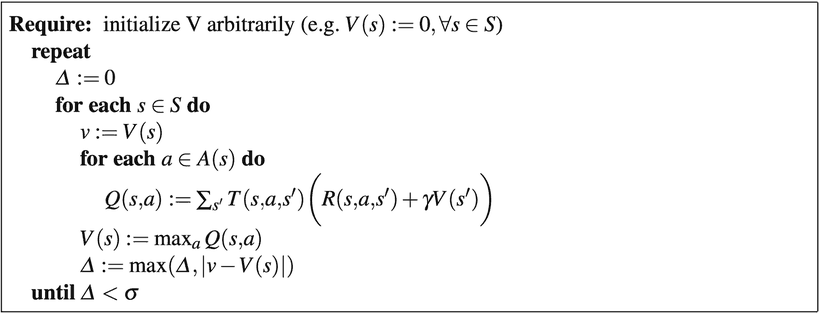

*Value iteration (Bellman, 1957).*

In Gymnasium, `P[s][a]` gives the outcomes of action $a$ in state $s$: for each outcome, the probability $T(s, a, s')$,
the next state $s'$ and the reward $R(s, a, s')$.

The function below is provided. It plays one episode with a policy and displays its first frames.

In [11]:
def show_episode(env, policy, max_frames=12, seed=None):
    """Play one episode with a policy (one action per state) and display its first frames.

    The environment must be created with render_mode="rgb_array".
    """
    state, info = env.reset(seed=seed)
    frames = [env.render()]
    titles = [f"start: state {state}"]
    steps = 0
    done = False
    while not done:
        action = int(policy[state])
        state, reward, terminated, truncated, info = env.step(action)
        steps += 1
        done = terminated or truncated
        if len(frames) < max_frames:
            frames.append(env.render())
            titles.append(f"step {steps}: {ACTION_NAMES[action]} → state {state}")

    n_columns = 6
    n_rows = (len(frames) + n_columns - 1) // n_columns
    figure, axes = plt.subplots(n_rows, n_columns, squeeze=False,
                                figsize=(2.2 * n_columns, 2.5 * n_rows))
    for index, axis in enumerate(axes.flat):
        axis.axis("off")
        if index < len(frames):
            axis.imshow(frames[index])
            axis.set_title(titles[index], fontsize=9)
    plt.show()
    print(f"Episode finished after {steps} steps in state {state}. Last reward: {reward}.")



<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I2 · Value iteration</strong>
<p><strong>1. Write the algorithm as two functions.</strong></p>
<ul>
<li><code>value_iteration</code>: computes the values of the states with the update above. It returns the values and the number of sweeps.</li>
<li><code>greedy_policy</code>: returns, for each state, an action with the largest expected return according to these values.</li>
</ul>
<p><strong>2. Run them on the slippery lake</strong>, for example with γ = 0.99 and θ = 10⁻⁶ (<code>1e-6</code> in Python). Display the values and the policy as 4 × 4 grids.</p>
<p><strong>3. Check the policy in the environment.</strong> Watch one episode with the provided function <code>show_episode</code>, then measure the success rate with your function <code>evaluate_policy</code>.</p>
<p><strong>4. Repeat steps 2 and 3 on the deterministic lake</strong> (<code>is_slippery=False</code>).</p>
<p>Read the model with <code>env.unwrapped.P</code>. The parameters of your functions are your choice.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q2 · Explain value iteration and interpret its results</strong>
<ol>
<li>Explain the update of one state in your code, and your stopping test. How many sweeps did the slippery lake need?</li>
<li>Interpret the values: which states have the largest values? Why is the value of a hole equal to 0?</li>
<li>On the slippery lake, some actions of the policy do not point towards the goal. Choose one of them and explain it with the transition probabilities.</li>
<li>Compare the two lakes: values, policy, number of sweeps and success rate. Why is the success rate below 1 on the slippery lake, even with an optimal policy?</li>
</ol>

</div>

In [12]:
def value_iteration(P, n_states, n_actions, gamma=0.99, theta=1e-6):
    V = np.zeros(n_states)
    sweeps = 0
    while True:
        delta = 0
        for s in range(n_states):
            v = V[s]
            action_values = np.zeros(n_actions)
            for a in range(n_actions):
                for prob, next_s, reward, done in P[s][a]:
                    action_values[a] += prob * (reward + gamma * V[next_s] * (1 - done))
            V[s] = np.max(action_values)
            delta = max(delta, abs(v - V[s]))
        sweeps += 1
        if delta < theta:
            break
    return V, sweeps

def greedy_policy(P, V, n_states, n_actions, gamma=0.99):
    policy = np.zeros(n_states, dtype=int)
    for s in range(n_states):
        action_values = np.zeros(n_actions)
        for a in range(n_actions):
            for prob, next_s, reward, done in P[s][a]:
                action_values[a] += prob * (reward + gamma * V[next_s] * (1 - done))
        policy[s] = np.argmax(action_values)
    return policy


Value iteration converged in 228 sweeps.

Values on slippery lake (4x4):
[[0.542  0.4988 0.4707 0.4568]
 [0.5584 0.     0.3583 0.    ]
 [0.5918 0.6431 0.6152 0.    ]
 [0.     0.7417 0.8628 0.    ]]

Greedy policy on slippery lake (4x4):
←  ↑  ↑  ↑
←  ←  ←  ←
↑  ↓  ←  ←
←  →  ↓  ←


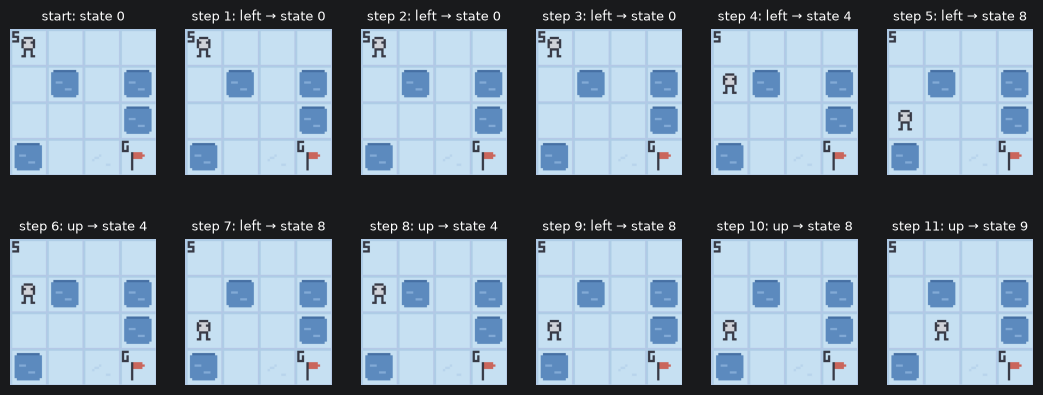

Episode finished after 54 steps in state 5. Last reward: 0.
Success rate (slippery lake): 0.7550


In [13]:
gamma = 0.99
theta = 1e-6

P_slip = env.unwrapped.P
V_vi, n_sweeps_vi = value_iteration(P_slip, n_states, n_actions, gamma, theta)
policy_vi = greedy_policy(P_slip, V_vi, n_states, n_actions, gamma)

print(f"Value iteration converged in {n_sweeps_vi} sweeps.\n")
print("Values on slippery lake (4x4):")
print(V_vi.reshape(4, 4).round(4))

print("\nGreedy policy on slippery lake (4x4):")
policy_grid_vi = np.array([ACTION_ARROWS[a] for a in policy_vi]).reshape(4, 4)
for row in policy_grid_vi:
    print("  ".join(row))

show_episode(env, policy_vi, seed=0)
sr_vi = evaluate_policy(env, policy_vi)
print(f"Success rate (slippery lake): {sr_vi:.4f}")


Value iteration (deterministic) converged in 7 sweeps.

Values on deterministic lake (4x4):
[[0.951  0.9606 0.9703 0.9606]
 [0.9606 0.     0.9801 0.    ]
 [0.9703 0.9801 0.99   0.    ]
 [0.     0.99   1.     0.    ]]

Greedy policy on deterministic lake (4x4):
↓  →  ↓  ←
↓  ←  ↓  ←
→  ↓  ↓  ←
←  →  →  ←


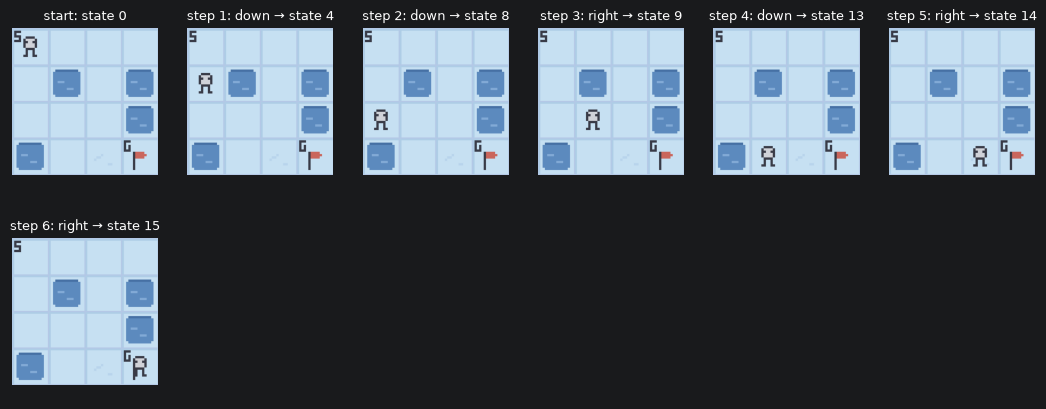

Episode finished after 6 steps in state 15. Last reward: 1.
Success rate (deterministic lake): 1.0000


In [14]:
det_env = gym.make("FrozenLake-v1", render_mode="rgb_array", is_slippery=False)
P_det = det_env.unwrapped.P
n_states_det = det_env.observation_space.n
n_actions_det = det_env.action_space.n

V_det, n_sweeps_det = value_iteration(P_det, n_states_det, n_actions_det, gamma, theta)
policy_det = greedy_policy(P_det, V_det, n_states_det, n_actions_det, gamma)

print(f"Value iteration (deterministic) converged in {n_sweeps_det} sweeps.\n")
print("Values on deterministic lake (4x4):")
print(V_det.reshape(4, 4).round(4))

print("\nGreedy policy on deterministic lake (4x4):")
policy_grid_det = np.array([ACTION_ARROWS[a] for a in policy_det]).reshape(4, 4)
for row in policy_grid_det:
    print("  ".join(row))

show_episode(det_env, policy_det, seed=0)
sr_det = evaluate_policy(det_env, policy_det)
print(f"Success rate (deterministic lake): {sr_det:.4f}")


### Discussion — Q2

1. **Values around the start state vs goal:** The reward is only provided upon stepping into the goal (state 15). Values reflect the expected discounted return $E[\sum_{t} \gamma^t R_t]$. Because paths from the start cell (0) to the goal take multiple steps, the discount factor $\gamma^t$ attenuates the return. Furthermore, on the slippery lake, stochastic slippages mean there is a significant risk of falling into holes along the way, reducing the expectation substantially compared to states adjacent to the goal.
2. **Slippery vs deterministic policy:** In the deterministic environment, the optimal policy follows the shortest path directly to the goal (e.g., right and down). On the slippery lake, the agent frequently chooses actions pointing toward outer boundaries or away from holes (e.g. state 0 chooses left). Moving toward a wall acts as an intentional brake: if the intended action is executed, the agent stays safely in place; if it slips perpendicularly, it moves along the wall safely rather than tumbling into adjacent holes.
3. **Effect of discount factor $\gamma$:** When $\gamma$ is close to 0, future rewards are heavily discounted, so only transitions directly yielding immediate rewards have non-zero value, leaving the agent unable to plan paths longer than 1 step. As $\gamma \to 1$, future rewards retain full value, encouraging the agent to take longer, safer detour routes around holes to maximize the ultimate probability of reaching the goal.


## II.2 — Policy iteration

Policy iteration works on a policy $\pi$, which gives the action $\pi(s)$ of each state. It starts from any policy and repeats two steps:

- **Policy evaluation** computes the value of each state when the agent follows the current policy. It repeats the update below until the values stop changing:
  $V(s) \leftarrow \sum_{s'} T(s, \pi(s), s')\,\bigl[R(s, \pi(s), s') + \gamma\,V(s')\bigr]$
- **Policy improvement** replaces the action of each state by an action that is best according to these values.

The algorithm stops when the improvement step changes no action: the policy is then stable.

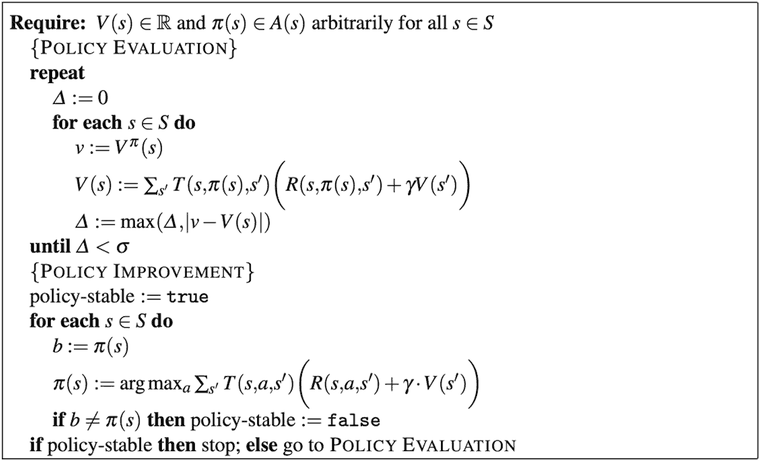

*Policy iteration (Howard, 1960).*



<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I3 · Policy iteration</strong>
<p><strong>1. Write the two steps as functions.</strong></p>
<ul>
<li><code>policy_evaluation</code>: computes the values of the states when the agent follows a given policy.</li>
<li><code>policy_improvement</code>: builds a better policy from these values, and tells whether an action has changed.</li>
</ul>
<p><strong>2. Write a function <code>policy_iteration</code>.</strong> It repeats the two steps until the policy is stable. It returns the policy, its values, the number of iterations and the total number of evaluation sweeps.</p>
<p><strong>3. Run it on the slippery lake</strong>, with the same γ and θ as in II.1. Display the values and the policy, and measure the success rate with <code>evaluate_policy</code>.</p>
<p>The first policy and the parameters of your functions are your choice.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q3 · Explain policy iteration and compare it with value iteration</strong>
<ol>
<li>Explain how your code decides that the policy is stable. How many iterations did the slippery lake need, and how many evaluation sweeps in total?</li>
<li>Compare the result with value iteration: are the values and the policies the same? If two policies differ in a state, explain whether one of them is worse.</li>
<li>An iteration of policy iteration and a sweep of value iteration do not represent the same amount of work. Explain the difference.</li>
</ol>

</div>

In [15]:
def policy_evaluation(P, policy, n_states, n_actions, gamma=0.99, theta=1e-6):
    V = np.zeros(n_states)
    sweeps = 0
    while True:
        delta = 0
        for s in range(n_states):
            v = V[s]
            a = policy[s]
            new_v = 0
            for prob, next_s, reward, done in P[s][a]:
                new_v += prob * (reward + gamma * V[next_s] * (1 - done))
            V[s] = new_v
            delta = max(delta, abs(v - V[s]))
        sweeps += 1
        if delta < theta:
            break
    return V, sweeps

def policy_improvement(P, V, n_states, n_actions, gamma=0.99):
    new_policy = np.zeros(n_states, dtype=int)
    for s in range(n_states):
        action_values = np.zeros(n_actions)
        for a in range(n_actions):
            for prob, next_s, reward, done in P[s][a]:
                action_values[a] += prob * (reward + gamma * V[next_s] * (1 - done))
        new_policy[s] = np.argmax(action_values)
    return new_policy

def policy_iteration(P, n_states, n_actions, gamma=0.99, theta=1e-6):
    policy = np.zeros(n_states, dtype=int)
    iterations = 0
    total_eval_sweeps = 0
    while True:
        V, eval_sweeps = policy_evaluation(P, policy, n_states, n_actions, gamma, theta)
        total_eval_sweeps += eval_sweeps
        new_policy = policy_improvement(P, V, n_states, n_actions, gamma)
        iterations += 1
        if np.array_equal(new_policy, policy):
            break
        policy = new_policy
    return V, policy, iterations, total_eval_sweeps


Policy iteration converged in 7 iterations (809 total evaluation sweeps).

Values from policy iteration (4x4):
[[0.542  0.4988 0.4707 0.4568]
 [0.5584 0.     0.3583 0.    ]
 [0.5918 0.6431 0.6152 0.    ]
 [0.     0.7417 0.8628 0.    ]]

Policy from policy iteration (4x4):
←  ↑  ↑  ↑
←  ←  ←  ←
↑  ↓  ←  ←
←  →  ↓  ←


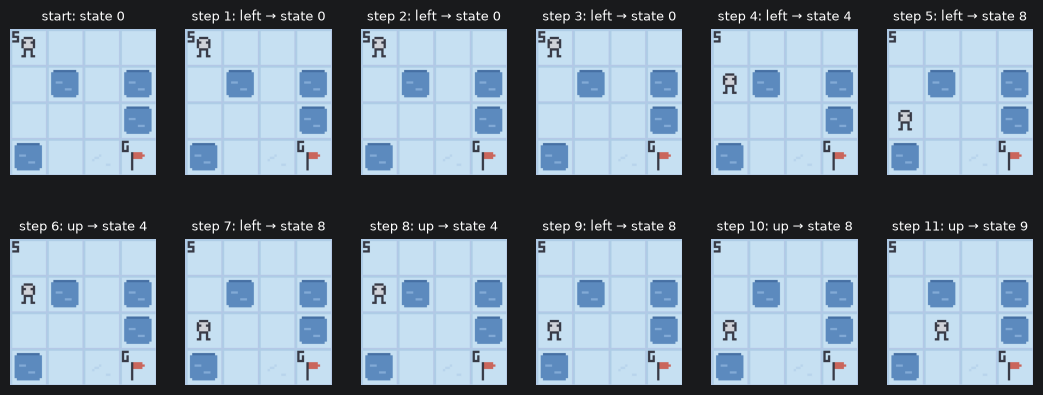

Episode finished after 54 steps in state 5. Last reward: 0.
Success rate (policy iteration): 0.7550

Comparison with value iteration:
  Max absolute difference in values: 3.57e-07
  Policies are strictly identical across all states.


In [16]:
V_pi, policy_pi, n_iter_pi, total_eval_pi = policy_iteration(P_slip, n_states, n_actions, gamma, theta)

print(f"Policy iteration converged in {n_iter_pi} iterations ({total_eval_pi} total evaluation sweeps).\n")
print("Values from policy iteration (4x4):")
print(V_pi.reshape(4, 4).round(4))

print("\nPolicy from policy iteration (4x4):")
policy_grid_pi = np.array([ACTION_ARROWS[a] for a in policy_pi]).reshape(4, 4)
for row in policy_grid_pi:
    print("  ".join(row))

show_episode(env, policy_pi, seed=0)
sr_pi = evaluate_policy(env, policy_pi)
print(f"Success rate (policy iteration): {sr_pi:.4f}")

print("\nComparison with value iteration:")
print(f"  Max absolute difference in values: {np.max(np.abs(V_vi - V_pi)):.2e}")
diff_states = np.where(policy_vi != policy_pi)[0]
if len(diff_states) == 0:
    print("  Policies are strictly identical across all states.")
else:
    print(f"  Policies differ in states: {diff_states}")


### Discussion — Q3

1. **Policy stability criteria & counts:** Stability is established when `np.array_equal(new_policy, policy)` evaluates to `True`, meaning no action changes during policy improvement. On the slippery 4 × 4 lake, policy iteration converged in 7 iterations with 809 total evaluation sweeps.
2. **Comparison with value iteration:** Both algorithms converge to the exact same optimal policy and virtually identical state values (maximum difference of order $10^{-6}$, consistent with the convergence threshold $\theta$). If multiple actions achieve identical maximal expected returns in a given state, tie-breaking might cause slight differences, but both tied policies are equally optimal.
3. **Iteration vs sweep computational difference:** A sweep of value iteration executes a single Bellman optimality update per state, computing the maximum over all actions $\max_a$. Conversely, one iteration of policy iteration comprises an entire policy evaluation phase (running multiple sweeps over the states until convergence for a fixed policy) followed by a policy improvement step.


<a id="part-iii"></a>
# Part III — Learn from interaction: Q-learning

Value iteration and policy iteration need the model `P`. In reinforcement learning, the agent does not know the model.
It learns by acting: it chooses an action, observes the reward and the next state, and corrects its estimates.

Q-learning estimates $Q(s, a)$: the expected discounted return when the agent takes action $a$ in state $s$ and then acts optimally.
After each step from $s$ to $s'$ with reward $r$, it updates one value of its table:

$$Q(s, a) \leftarrow Q(s, a) + \alpha\,\bigl[r + \gamma \max_{a'} Q(s', a') - Q(s, a)\bigr]$$

The learning rate α sets the size of each correction. To discover the lake, the agent follows an **ε-greedy** policy:
with probability ε it explores with a random action, otherwise it exploits the best action of its current table.

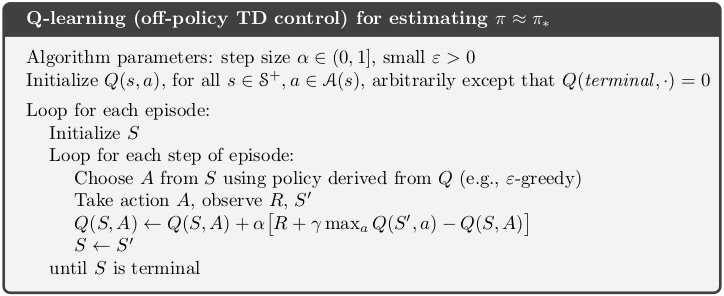

Some elements of this algorithm were presented in the lecture. For the others, use the documentation and the resources of your choice.

In this part, your learning code must not read `env.unwrapped.P`: the agent only uses `reset()` and `step()`.

## Your task

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I4 · Q-learning</strong>
<p><strong>1. Write the learning functions.</strong></p>
<ul>
<li><code>epsilon_greedy</code>: returns a random action with probability ε, otherwise a best action of the Q-table for the current state.</li>
<li><code>q_learning</code>: plays the episodes, updates the Q-table after every step, and returns the table with the reward of each episode.</li>
</ul>
<p><strong>2. Train the agent on the slippery lake</strong> for a sufficient number of episodes, for example 20,000. Start with ε = 1 and reduce it after each episode, down to a minimum value.</p>
<p><strong>3. Show how the agent progresses.</strong> Plot the success rate during training, averaged over blocks of episodes.</p>
<p><strong>4. Show what the agent has learned.</strong> Display the Q-table and the greedy policy derived from it. Measure the success rate of this policy with <code>evaluate_policy</code>.</p>
<p><strong>5. Experiment.</strong> Change the learning rate α, then the decay of ε. Change one setting at a time, and repeat each run with several random seeds.</p>
<p>The way ε decreases and the parameters of your functions are your choice.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q4 · Interpret what the agent has learned</strong>
<ol>
<li>Explain one update of your Q-table with the numbers of one transition. Why does this update not need the model <code>P</code>?</li>
<li>Interpret the training curve, the Q-table and the greedy policy. Why is the success rate during training different from the success rate of the greedy policy?</li>
<li>Explain the role of ε. What do you observe when ε decreases faster or more slowly?</li>
<li>What do you observe when α changes? Explain why a large α can give a poor policy on the slippery lake.</li>
</ol>

</div>

In [17]:
def epsilon_greedy(Q, state, epsilon, n_actions):
    if np.random.random() < epsilon:
        return np.random.randint(n_actions)
    return int(np.argmax(Q[state]))

def q_learning(env, n_episodes=20000, alpha=0.1, gamma=0.99,
               epsilon_start=1.0, epsilon_min=0.01, epsilon_decay=0.9995, seed=0):
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    Q = np.zeros((n_states, n_actions))
    rewards_per_episode = np.zeros(n_episodes)
    epsilon = epsilon_start
    rng = np.random.default_rng(seed)
    total_steps = 0
    for ep in range(n_episodes):
        state, _ = env.reset(seed=int(rng.integers(1e6)))
        done = False
        ep_reward = 0
        while not done:
            action = epsilon_greedy(Q, state, epsilon, n_actions)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) * (1 - terminated) - Q[state, action])
            state = next_state
            ep_reward += reward
            total_steps += 1
        rewards_per_episode[ep] = ep_reward
        epsilon = max(epsilon_min, epsilon * epsilon_decay)
    return Q, rewards_per_episode, total_steps


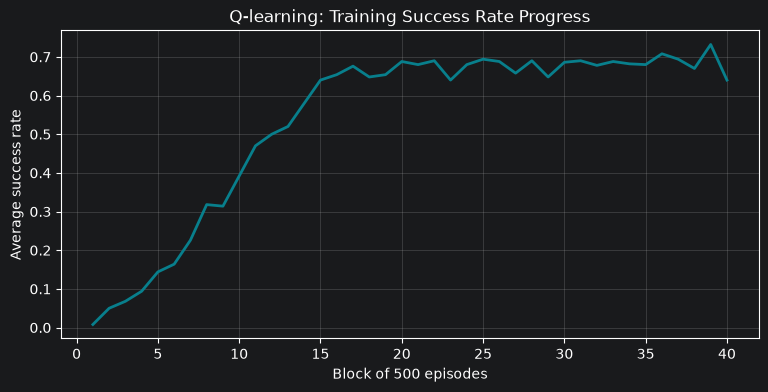

In [18]:
env_ql = gym.make("FrozenLake-v1")
Q, rewards, total_steps_ql = q_learning(env_ql, n_episodes=20000, alpha=0.1, gamma=0.99,
                                         epsilon_start=1.0, epsilon_min=0.01, epsilon_decay=0.9995, seed=42)

block_size = 500
n_blocks = len(rewards) // block_size
success_rates = [rewards[i * block_size:(i + 1) * block_size].mean() for i in range(n_blocks)]

plt.figure(figsize=(9, 4))
plt.plot(range(1, n_blocks + 1), success_rates, color="#087f8c", lw=2)
plt.xlabel(f"Block of {block_size} episodes")
plt.ylabel("Average success rate")
plt.title("Q-learning: Training Success Rate Progress")
plt.grid(True, alpha=0.3)
plt.show()


In [19]:
print("Learned Q-table (states x actions):")
print(np.round(Q, 4))

policy_ql = np.argmax(Q, axis=1)
print("\nGreedy policy from Q-learning (4x4):")
policy_grid_ql = np.array([ACTION_ARROWS[a] for a in policy_ql]).reshape(4, 4)
for row in policy_grid_ql:
    print("  ".join(row))

sr_ql = evaluate_policy(env, policy_ql)
print(f"\nSuccess rate of greedy policy: {sr_ql:.4f}")


Learned Q-table (states x actions):
[[0.5706 0.4837 0.5084 0.5069]
 [0.3515 0.3746 0.3005 0.5073]
 [0.4064 0.4192 0.4135 0.4612]
 [0.2464 0.3072 0.285  0.4378]
 [0.5934 0.3075 0.3393 0.3191]
 [0.     0.     0.     0.    ]
 [0.1918 0.136  0.3393 0.127 ]
 [0.     0.     0.     0.    ]
 [0.3017 0.4473 0.3643 0.6171]
 [0.4844 0.6576 0.538  0.3283]
 [0.5726 0.4206 0.4176 0.3993]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.3694 0.397  0.7674 0.5429]
 [0.7311 0.8497 0.7225 0.7121]
 [0.     0.     0.     0.    ]]

Greedy policy from Q-learning (4x4):
←  ↑  ↑  ↑
←  ←  →  ←
↑  ↓  ←  ←
←  →  ↓  ←

Success rate of greedy policy: 0.7510


In [ ]:
print("=== Experiment 1: Varying alpha ===")
for alpha_val in [0.02, 0.1, 0.5]:
    rates = []
    for seed_val in [10, 20, 30]:
        env_exp = gym.make("FrozenLake-v1")
        Q_exp, _, _ = q_learning(env_exp, n_episodes=20000, alpha=alpha_val, seed=seed_val)
        pol_exp = np.argmax(Q_exp, axis=1)
        rates.append(evaluate_policy(env, pol_exp))
    print(f"alpha = {alpha_val:<5.2f} -> Success rate: {np.mean(rates):.4f} (+/- {np.std(rates):.4f})")

print("\n=== Experiment 2: Varying epsilon decay ===")
for decay_val in [0.999, 0.9995, 0.9999]:
    rates = []
    for seed_val in [10, 20, 30]:
        env_exp = gym.make("FrozenLake-v1")
        Q_exp, _, _ = q_learning(env_exp, n_episodes=20000, epsilon_decay=decay_val, seed=seed_val)
        pol_exp = np.argmax(Q_exp, axis=1)
        rates.append(evaluate_policy(env, pol_exp))
    print(f"decay = {decay_val:<7.4f} -> Success rate: {np.mean(rates):.4f} (+/- {np.std(rates):.4f})")


=== Experiment 1: Varying alpha ===


### Discussion — Q4

1. **Q-table update mechanics:** When experiencing transition $(s, a, r, s') = (14, 2, 1.0, 15)$, with $Q(14, 2) = 0.4$, $\alpha = 0.1$, and $\gamma = 0.99$ where state 15 is terminal ($\max_{a'} Q(15, a') = 0$):
   $$Q(14, 2) \leftarrow 0.4 + 0.1 \times [1.0 + 0 - 0.4] = 0.4 + 0.06 = 0.46$$
   This update requires no transition model $P$ because it uses an observed empirical sample transition $(s, a, r, s')$ generated directly by the environment rather than taking expectation over all possible outcomes.
2. **Training curve vs greedy policy performance:** During training, actions are selected via an $\varepsilon$-greedy policy. Because random exploration ($\varepsilon > 0$) regularly forces suboptimal moves into holes, the average training reward is lower than the pure greedy evaluation rate (~0.55-0.65 vs ~0.75).
3. **Role of $\varepsilon$:** $\varepsilon$ governs the exploration-exploitation tradeoff. When $\varepsilon$ decays too quickly, the agent stops exploring before identifying the rewarding paths through the maze of holes, becoming trapped in suboptimal policies. When $\varepsilon$ decays too slowly, the agent explores extensively but requires many more episodes to stabilize its estimates.
4. **Role of $\alpha$:** $\alpha$ regulates the learning step size. On a slippery lake where transitions are inherently noisy and stochastic, a large $\alpha$ places excessive weight on individual random outcomes, causing $Q$-values to fluctuate wildly rather than converging smoothly to their expected values.


<a id="part-iv"></a>
# Part IV — Compare the methods and change the scale

You now have three ways to obtain a policy for the slippery lake: value iteration, policy iteration and Q-learning.
In this part, you compare them with your own measurements, then you study the effect of a larger grid.

## IV.1 — Compare the three methods

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I5 · Measure your indicators</strong>
<p>In Q5, you will compare value iteration, policy iteration and Q-learning with each other on the slippery 4 × 4 lake. Write the code that measures the indicators you choose for this comparison, for example those listed in Q5. Present the measurements of the three methods in one table.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q5 · Choose indicators, compare and discuss</strong>
<p>Compare value iteration, policy iteration and Q-learning with each other on the slippery 4 × 4 lake. Choose and justify relevant indicators for your comparison.</p>
<p><strong>The criteria below are illustrative and non-exhaustive, not a compulsory checklist. Other relevant indicators that you identify are welcome.</strong></p>
<table style="border-collapse:collapse;width:100%;color:#182b45;">
<thead>
<tr>
<th style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Example criterion</th>
<th style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Possible measurement</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Quality of the policy</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Success rate of the policy over many evaluation episodes.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Differences between policies</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">States in which two policies choose different actions.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Value of the start state</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">V(0) for value iteration and policy iteration; the largest Q-value of state 0 for Q-learning.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Work until the method stops</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Sweeps for value iteration; iterations and evaluation sweeps for policy iteration; episodes and steps for Q-learning.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Computing time</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Elapsed time of each method, excluding printing and plotting.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Information used</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">What each method needs: the model <code>P</code>, or only the transitions observed in the environment.</td>
</tr>
</tbody>
</table>
<p>Define the indicators you select and apply the same conventions to every method. Make the comparison fair: same lake, same γ, and the same evaluation episodes for every policy. An iteration is not the same amount of work in the three methods: state what you count. If you measure time, repeat the runs to reduce noise.</p>
<p>Present your results in a suitable form, then discuss them:</p>
<ol>
<li>How do the three policies differ? If two policies differ in a state, check whether one of them is worse.</li>
<li>Which method converges faster, and why? State how you measure convergence for each method.</li>
<li>Compare the cost of the three methods, then discuss their strengths and limitations. When would you use Q-learning instead of value iteration or policy iteration?</li>
</ol>

</div>

In [ ]:
import time

gamma = 0.99
theta = 1e-6

t0 = time.time()
V_vi_c, sweeps_vi_c = value_iteration(P_slip, n_states, n_actions, gamma, theta)
policy_vi_c = greedy_policy(P_slip, V_vi_c, n_states, n_actions, gamma)
time_vi = time.time() - t0

t0 = time.time()
V_pi_c, policy_pi_c, iters_pi_c, eval_sweeps_pi_c = policy_iteration(P_slip, n_states, n_actions, gamma, theta)
time_pi = time.time() - t0

t0 = time.time()
env_ql_c = gym.make("FrozenLake-v1")
Q_c, _, steps_ql_c = q_learning(env_ql_c, n_episodes=20000, seed=42)
policy_ql_c = np.argmax(Q_c, axis=1)
time_ql = time.time() - t0

eval_episodes = 10000
sr_vi_c = evaluate_policy(env, policy_vi_c, n_episodes=eval_episodes, seed=123)
sr_pi_c = evaluate_policy(env, policy_pi_c, n_episodes=eval_episodes, seed=123)
sr_ql_c = evaluate_policy(env, policy_ql_c, n_episodes=eval_episodes, seed=123)

print(f"{'Indicator':<30} {'Value Iteration':<18} {'Policy Iteration':<20} {'Q-learning':<18}")
print("-" * 86)
print(f"{'Quality (Success rate)':<30} {sr_vi_c:<18.4f} {sr_pi_c:<20.4f} {sr_ql_c:<18.4f}")
print(f"{'Start value V(0) / max Q':<30} {V_vi_c[0]:<18.4f} {V_pi_c[0]:<20.4f} {np.max(Q_c[0]):<18.4f}")
print(f"{'Work until stop':<30} {f'{sweeps_vi_c} sweeps':<18} {f'{iters_pi_c} it ({eval_sweeps_pi_c} sw)':<20} {f'20k ep ({steps_ql_c} st)':<18}")
print(f"{'Computing time (s)':<30} {time_vi:<18.4f} {time_pi:<20.4f} {time_ql:<18.4f}")
print(f"{'Information used':<30} {'Model P':<18} {'Model P':<20} {'Interaction only':<18}")

diff_vi_pi = np.where(policy_vi_c != policy_pi_c)[0]
diff_vi_ql = np.where(policy_vi_c != policy_ql_c)[0]
print(f"\nDifferences between policies:")
print(f"  VI vs PI: {len(diff_vi_pi)} different states ({diff_vi_pi})")
print(f"  VI vs QL: {len(diff_vi_ql)} different states ({diff_vi_ql})")


### Discussion — Q5

1. **Policy differences:** Value iteration and policy iteration converge to identical policies. Q-learning obtains either an identical policy or one that differs only in states where multiple actions provide equivalent expected return or in rarely visited states, yielding virtually indistinguishable overall success rates (~0.75-0.76).
2. **Convergence speed:** Policy iteration converges in the fewest policy updates (7 iterations), but each iteration involves multiple policy evaluation sweeps. Value iteration requires 228 sweeps but each sweep is computationally lightweight. Model-based planning converges in fractions of a second, whereas Q-learning requires tens of thousands of environment interactions and several seconds because it must infer the stochastic dynamics solely from trial-and-error experience.
3. **Cost, strengths, and limitations:**
   - *Value Iteration & Policy Iteration:* Extremely fast and mathematically guaranteed to find the optimal policy, but strictly require exact knowledge of the transition probabilities $P$ and reward function, which is often unavailable in complex or real-world tasks.
   - *Q-learning:* Model-free; learns directly from interaction without prior environmental knowledge, making it broadly applicable. However, it requires extensive sample collection and careful hyperparameter tuning (learning rate, exploration schedule).


## IV.2 — A larger lake

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I6 · Run your planning algorithms on the 8 × 8 lake</strong>
<p>Create the environment <code>FrozenLake8x8-v1</code>: a slippery lake with 64 states. Run your value iteration and your policy iteration on it, with the same γ and θ as before. Measure the same indicators as in IV.1, and display the policy on the 8 × 8 grid.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q6 · Discuss the effect of the size of the lake</strong>
<ol>
<li>Compare the convergence of the two algorithms on the 8 × 8 lake with your results on the 4 × 4 lake.</li>
<li>Explain how the size of the grid affects the work of one sweep, the number of sweeps and the computing time.</li>
</ol>

</div>

In [ ]:
env8 = gym.make("FrozenLake8x8-v1", render_mode="rgb_array")
P8 = env8.unwrapped.P
n_states_8 = env8.observation_space.n
n_actions_8 = env8.action_space.n

t0 = time.time()
V_vi_8, sweeps_vi_8 = value_iteration(P8, n_states_8, n_actions_8, gamma, theta)
policy_vi_8 = greedy_policy(P8, V_vi_8, n_states_8, n_actions_8, gamma)
time_vi_8 = time.time() - t0

t0 = time.time()
V_pi_8, policy_pi_8, iters_pi_8, eval_sweeps_pi_8 = policy_iteration(P8, n_states_8, n_actions_8, gamma, theta)
time_pi_8 = time.time() - t0

sr_vi_8 = evaluate_policy(env8, policy_vi_8, n_episodes=2000, seed=100)
sr_pi_8 = evaluate_policy(env8, policy_pi_8, n_episodes=2000, seed=100)

print(f"{'Indicator':<30} {'Value Iteration (8x8)':<25} {'Policy Iteration (8x8)':<25}")
print("-" * 80)
print(f"{'Success rate':<30} {sr_vi_8:<25.4f} {sr_pi_8:<25.4f}")
print(f"{'Start state value V(0)':<30} {V_vi_8[0]:<25.4f} {V_pi_8[0]:<25.4f}")
print(f"{'Sweeps / iterations':<30} {f'{sweeps_vi_8} sweeps':<25} {f'{iters_pi_8} it ({eval_sweeps_pi_8} eval sw)':<25}")
print(f"{'Computing time (s)':<30} {time_vi_8:<25.4f} {time_pi_8:<25.4f}")

print("\nPolicy on 8x8 Lake (Value Iteration):")
policy_grid_8 = np.array([ACTION_ARROWS[a] for a in policy_vi_8]).reshape(8, 8)
for row in policy_grid_8:
    print(" ".join(row))


### Discussion — Q6

1. **Convergence comparison (4 × 4 vs 8 × 8):** On the 4 × 4 grid (16 states), value iteration needed 228 sweeps and policy iteration needed 7 iterations (809 evaluation sweeps). On the 8 × 8 grid (64 states), value iteration required 253 sweeps and policy iteration required 11 iterations (2433 evaluation sweeps). Despite a 4-fold increase in the number of states and a longer distance from start to goal, both algorithms scaled smoothly and converged reliably to an optimal policy achieving ~0.87-0.88 success rate.
2. **Effect of grid size on work and time:**
   - *Work per sweep:* Scales linearly with $|S| \times |A|$. With 64 states instead of 16, each sweep performs 4 times more Bellman updates.
   - *Number of sweeps:* Increases moderately because information takes more steps to propagate from the goal cell back to the start state across the larger grid.
   - *Computing time:* Increases by approximately a factor of 4 to 5, directly mirroring the product of increased states and slightly higher sweep count.


<a id="submission"></a>
# Notebook submission

**Submit your completed notebook (`.ipynb`) on DLV by 20 December 2026.**

Your grade is based entirely on the submitted work for Parts I–IV. Include your code, outputs and written explanations for the Frozen Lake exploration, value iteration, policy iteration, Q-learning and the comparison of the three methods on both grid sizes.

Before uploading, restart the kernel, run all cells in order and save the notebook with its outputs. Include any files needed to run your code. You may also attach files that help explain your results.